# Problem 2: Weighted coastal surveillance network maintenance


## Notebook roadmap

This notebook is organized as follows:

1. **Problem and Hamiltonian** — model the weighted five-station maintenance problem as a weighted MaxCut instance.
2. **Classical reference** — diagonalize the Hamiltonian to obtain the exact optimum.
3. **QAOA circuit** — build the parameterized circuit and define the simulator.
4. **Parameter search** — choose the number of layers and the QAOA angles with an exact statevector search that maximizes the probability of an optimal bitstring.
5. **Visualizations** — inspect the p=1 landscape, the layer sweep, the search spread, the angle schedule, and the final distribution.
6. **Evaluation** — sample the final circuit, decode the measured schedules, and score the overlap with the optimal solutions.
7. **Hardware run** — optional execution on an IBM Quantum backend.
8. **Takeaways** — space for the verbal summary of the main lessons.


# Importing the required libraries

The following cell holds the necessary imports to execute this notebook.<br>
You are welcome to modify this notebook as you see fit.


In [1]:
# Displaying the problem graph
import matplotlib.pyplot as plt
import networkx as nx

# Matrix computation and classical optimization
import numpy as np
from scipy.optimize import minimize

# Structure needed for writing Hamiltonians
from qiskit.quantum_info import SparsePauliOp, Statevector

# Creation method to build the QAOA circuit that will be optimized
from qiskit.circuit.library import QAOAAnsatz

# Quantum circuit execution tools
from qiskit_ibm_runtime.executor_sampler import Sampler

# Transpilation of quantum circuits for IBM's quantum computers and simulators
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Quantum computer simulator
from qiskit_aer import AerSimulator

# Visualization of probability distributions
from qiskit.visualization import plot_histogram

# Evaluation helpers provided with the challenge
import utils


# Introduction
A coastal surveillance network must schedule the maintenance of its radar and sensor stations, requiring the stations to be powered down during one of two periods.<br>
This simplified scenario lets you experiment with solving a combinatorial optimization problem using the **QAOA** quantum algorithm.

## Problem statement
> The network has five radar or sensor stations whose maintenance must be scheduled to happen during one of two periods. If two stations have overlapping coverage, they should be assigned to different periods whenever possible in order to minimize surveillance blind spots.

Consider the following stations :
- Northern radar (S0)
- Harbor sensor (S1)
- Coastal sensor (S2)
- Island radar (S3)
- Coastal radar (S4)

To model this problem, we represent each station as a node in a graph. An edge between two nodes indicates the corresponding stations have overlapping coverage.

<p align="center">
<img src="https://lh3.googleusercontent.com/d/10r0OqFuSRwy0Ptc2HVW6b4SjczL7T7nE" alt="FIXME" width="250"/>
</p>

## Supplementary information

In this problem, not all overlaps are equal. You are given an **overlap weight**, representing the surface or importance of the coverage overlap between two stations. This means that some station pairs have more substantial coverage overlap than others, and it is therefore more important to separate them into different groups.

The table below shows the overlap weight between station pairs. A larger weight represents a larger or more significant area of overlapping coverage:

|    <span></span>    | Northern radar (S0) | Harbor sensor (S1) | Coastal sensor (S2) | Island radar (S3) | Coastal radar (S4) |
|---------------------|:-------------------:|:------------------:|:-------------------:|:-----------------:|:------------------:|
| Northern radar (S0) | X                   | 10                 | 0                   | 11                | 13                 |
| Harbor sensor (S1)  | 10                  | X                  | 11                  | 0                 | 10                 |
| Coastal sensor (S2) | 0                   | 11                 | X                   | 8                 | 0                  |
| Island radar (S3)   | 11                  | 0                  | 8                   | X                 | 0                  |
| Coastal radar (S4)  | 13                  | 10                 | 0                   | 0                 | X                  |

**A higher weight** means that the two stations have more substantial overlapping coverage.

## Displaying the graph with Python
The [Networkx library](https://networkx.org/en/) is used to visualize the graph corresponding to this problem. The edge labels show the overlap weights, and the node labels use the station names from the problem statement.

Viewing the problem graph is optional, but may potentially help you in solving future challenges.


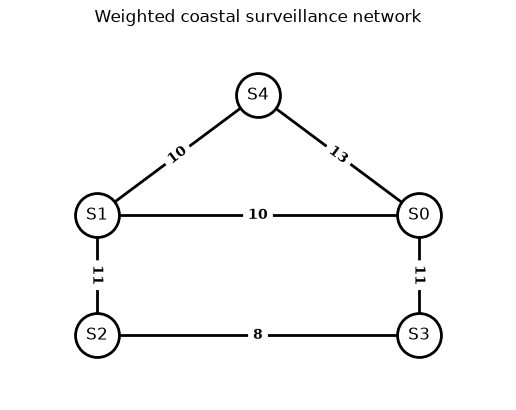

In [2]:
# Instantiate a graph using Networkx
G = nx.Graph()

# Add the edges of the graph and their weights, with format [(node_A, node_B, edge_weight_AB), ...]
G.add_weighted_edges_from([
    (0, 1, 10),
    (0, 3, 11),
    (0, 4, 13),
    (1, 2, 11),
    (1, 4, 10),
    (2, 3, 8),
])

# Define the positions of the nodes for drawing the graph
pos = {0: (1, 0), 1: (-1, 0), 2: (-1, -1), 3: (1, -1), 4: (0, 1)}

# Define visualization options
options = {
    "node_size": 1000,
    "node_color": "white",
    "edgecolors": "black",
    "linewidths": 2,
    "width": 2,
    "labels": {0: "S0", 1: "S1", 2: "S2", 3: "S3", 4: "S4"},
}

# Draw the graph
nx.draw_networkx(G, pos, **options)

# Display the edge weights
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10, font_weight="bold")

# Display the graph visualization
ax = plt.gca()
ax.margins(0.20)
plt.axis("off")
plt.title("Weighted coastal surveillance network")
plt.show()


## Objective
Your mission is to optimize the QAOA circuit so that it solves this problem efficiently. The notebook provides the QAOA pipeline; your task is to choose the best circuit parameters and the optimal number of circuit layers.

### Expected deliverables:
- A `SparsePauliOp` Hamiltonian describing the weighted problem.
- A set of optimal parameters for the QAOA circuit.
- The number of layers in the QAOA circuit.

#### Deliverable submission format:
A file in `.npz` format is expected. You can generate this file with the required information using the `save_res` method available in `utils.py`.

Please name your file `<your team>_problem_2.npz`. You can check the content of your `.npz` file using the `read_res` method also available in `utils.py`.

### Grading
Part of the grading will be done by running your QAOA circuit with the number of layers and parameters provided. A score will be calculated from the solution obtained using the predefined scoring method `compute_score` available in `utils.py`.

The judges will also evaluate the quality of the code and the originality of your parameter optimization for QAOA.


# The cost function

Before solving the problem using QAOA, we must first define a cost function that represents our optimization objective.

## Qubits and expectation value of observables

The weighted coastal surveillance network maintenance problem must be reformulated in terms of qubits and quantum logic gates in order to be solved by a quantum algorithm such as **QAOA**. Each node in the graph represents a surveillance station, and we use one qubit to encode each node. Thus, the number of qubits in our circuit corresponds to the number of nodes (or stations) in the graph.

To capture the relationships between nodes, we define the interactions between qubits based on the edges of the graph. For example, a Pauli operator such as $IIIZZ$ encodes an edge between qubits (nodes) 0 and 1, where each Pauli matrix $Z_i$ corresponds to a measurement on qubit $i$. The two possible qubit values represent the two maintenance periods.

When stations represented by qubits 0 and 1 are assigned to the same period, the observable $IIIZZ$ associated with this edge will take the value $+1$. If the stations are assigned to different periods, the observable will take the value $-1$. This formulation allows us to evaluate whether two nodes (stations) are correctly separated.

If necessary, refer to the presentation for reminders on measuring observables.

## Expressing the Hamiltonian

In Problem 2, each edge also carries an overlap weight $w_{ij}$. The Hamiltonian is the weighted sum of the Pauli operators associated with each pair of qubits connected by an edge in the graph. For two connected qubits $i$ and $j$, the interaction is modeled by the term $w_{ij} Z_i Z_j$.

Thus, the Hamiltonian for the entire graph is:

$$
H = \sum_{(i,j) \in E} w_{ij} Z_i Z_j
$$

where $E$ is the set of edges in the graph and $w_{ij}$ is the overlap weight of edge $(i,j)$. This sum covers all pairs of nodes $i$ and $j$ that share an edge, i.e. all station pairs with overlapping coverage. A larger weight makes it more important to assign the two stations to different periods.

> The objective is to minimize this function in order to assign stations to two periods so that heavily overlapping coverage is separated where possible.

**Note :** This corresponds to a weighted Max-Cut problem. The weights are normalized by the largest weight so that every coefficient lies in $[0, 1]$, which keeps the QAOA rotation angles in a convenient range.

We use the `SparsePauliOp` structure to instantiate the Hamiltonian.


In [3]:
# Normalize the weights by the largest overlap weight
max_weight = max(weight for _, _, weight in G.edges(data="weight"))

# Instantiate the SparsePauliOp as a sum of Pauli chains multiplied by a certain coefficient
H = SparsePauliOp.from_list([
    ("IIIZZ", 10.0 / max_weight),  # edge (0, 1)
    ("IIZZI", 11.0 / max_weight),  # edge (1, 2)
    ("IZZII", 8.0 / max_weight),   # edge (2, 3)
    ("IZIIZ", 11.0 / max_weight),  # edge (0, 3)
    ("ZIIIZ", 13.0 / max_weight),  # edge (0, 4)
    ("ZIIZI", 10.0 / max_weight),  # edge (1, 4)
])

# Display the SparsePauliOp
print(H)


SparsePauliOp(['IIIZZ', 'IIZZI', 'IZZII', 'IZIIZ', 'ZIIIZ', 'ZIIZI'],
              coeffs=[0.76923077+0.j, 0.84615385+0.j, 0.61538462+0.j, 0.84615385+0.j,
 1.        +0.j, 0.76923077+0.j])


# Classical verification

The problem can be represented in matrix form. Given its small size, it is possible to diagonalize this matrix to obtain an exact solution. You can use this diagonalization method to verify the validity of your quantum solution.

**Note** : This method can be found in `utils.py` and can be reused to check your solutions to the following problems as well.


In [4]:
# Verify that the Hamiltonian gives the expected solution
minimum_cost, binary_sols = utils.compute_exact_sols(hamiltonian=H)

# Display the minimal cost
print("Minimum cost : ", minimum_cost)

# Display the binary solutions (to read from right to left, from qubit 0 to qubit 4)
for i, sol in enumerate(binary_sols):
    print("Minimum cost solution {idx} : {solution}".format(idx=i, solution=sol))


Minimum cost :  -3.3076923076923075
Minimum cost solution 0 : 00101
Minimum cost solution 1 : 11010


# Solving the problem with QAOA

QAOA (Quantum Approximate Optimization Algorithm) is a variationnal quantum algorithm, used here to solve our combinatorial optimization problem. For theoretical details of the algorithm, please refer to the presentation.

In this second part of the challenge, you must adjust the parameters of your hybrid execution to effectively solve the weighted coastal surveillance network maintenance problem. The parameters to be adjusted are:

- The number of layers in your QAOA circuit.
- The rotation angles of the QAOA circuit.
- The options of the classical optimizer used to adjust the angles of the QAOA circuit.

Your goal is to find the best combination of layers and angles to consistently obtain solutions to the weighted MaxCut problem for multiple runs of the QAOA circuit.

## QAOA circuit

The next cell builds a placeholder QAOA ansatz. The actual number of layers is
chosen by the parameter search below, which rebuilds the final circuit with the
selected value.

**Note** : Too few layers may not provide a stable solution, while too many layers significantly increase execution time. The ideal solution is to find a balance that effectively amplifies the solutions without unnecessarily complicating the simulation, in order to remain within reasonable time limits for execution on a laptop.


In [5]:
# Placeholder number of layers; the search below rebuilds the final circuit
num_layers = 1

# Instantiate a QAOA circuit with Qiskit
circuit_qaoa = QAOAAnsatz(H, reps=num_layers)


In [6]:
# Simulator used by the sampler for the final evaluation
backend = AerSimulator()


## Exact cost function used by the search

The template's `cost_fonction` used the noisy `Estimator`. For five qubits, an
exact statevector evaluation is faster, deterministic, and directly gives the
probability of measuring an optimal bitstring. The search cell below therefore
uses its own exact cost function instead of the noisy estimator.

Because the cost Hamiltonian is diagonal in the computational basis, the QAOA
state can be propagated exactly with a small NumPy routine. This avoids the
shot noise of the estimator and makes the large multi-start search practical.


In [7]:
# Exact optimal bitstrings: used as the search objective and for validation.
optimal_bitstrings = list(binary_sols)
optimal_set = set(optimal_bitstrings)

# The cost Hamiltonian is diagonal in the computational basis, so the QAOA
# state can be propagated exactly. This is much faster and noise-free than
# calling the finite-shot Estimator at every optimization step.
_num_qubits = H.num_qubits
_state_dim = 2 ** _num_qubits
_cost_diagonal = np.real(np.diag(H.to_matrix()))
_plus_state = np.ones(_state_dim, dtype=complex) / np.sqrt(_state_dim)
_optimal_indices = [int(bitstring, 2) for bitstring in optimal_bitstrings]


def _apply_mixer(state, beta):
    """Apply exp(-i * beta * sum_i X_i) to a statevector."""
    mixer = np.array(
        [
            [np.cos(beta), -1j * np.sin(beta)],
            [-1j * np.sin(beta), np.cos(beta)],
        ]
    )
    tensor = state.reshape([2] * _num_qubits)
    for axis in range(_num_qubits):
        tensor = np.moveaxis(np.tensordot(mixer, tensor, axes=([1], [axis])), 0, axis)
    return tensor.reshape(-1)


def exact_state(params, num_layers):
    """Exact QAOA statevector.

    ``params`` must be ordered as
    [beta_0, ..., beta_{p-1}, gamma_0, ..., gamma_{p-1}],
    which is the order used by ``QAOAAnsatz.parameters``.
    """
    betas = params[:num_layers]
    gammas = params[num_layers:]
    state = _plus_state.copy()
    for beta, gamma in zip(betas, gammas):
        state *= np.exp(-1j * gamma * _cost_diagonal)
        state = _apply_mixer(state, beta)
    return state


def exact_metrics(params, num_layers):
    """Return (<H>, P(optimal)) evaluated exactly, without shot noise."""
    probabilities = np.abs(exact_state(params, num_layers)) ** 2
    energy = float(np.sum(probabilities * _cost_diagonal))
    p_optimal = float(np.sum(probabilities[_optimal_indices]))
    return energy, p_optimal


## QAOA circuit parameters

The next cell searches for the best QAOA angles and number of layers. A single
optimization from the all-zero vector is not reliable here: the all-zero point
is a stationary point of the QAOA energy, so the optimizer can stop immediately.

The search therefore combines several initializations:

- **Linear ramps** — smooth angle schedules that are known to work well for QAOA.
- **Random starts** — explore different basins of the parameter landscape.
- **Fixed per-layer seed** — every layer uses seed 42, so the search is reproducible.

Each candidate is scored with the exact statevector probability `P(optimal)`,
which is the quantity used by the grader. The best candidates are polished with
COBYLA directly on `P(optimal)`. The final choice uses `P(optimal)` first, then
`<H>`, then the smallest number of layers.


p= 1 | best <H>=-0.8312 | P(optimal)=30.02%
p= 2 | best <H>=-1.5833 | P(optimal)=55.17%
p= 3 | best <H>=-2.7916 | P(optimal)=80.49%
p= 4 | best <H>=-3.0069 | P(optimal)=90.11%

Selected number of layers : 4
Exact <H>                 : -3.0069
Exact P(optimal)          : 90.11%
Selected parameters       : [1.819229, 2.797558, 1.96798, 0.469055, 3.462281, 1.983068, 4.840065, 1.876599]


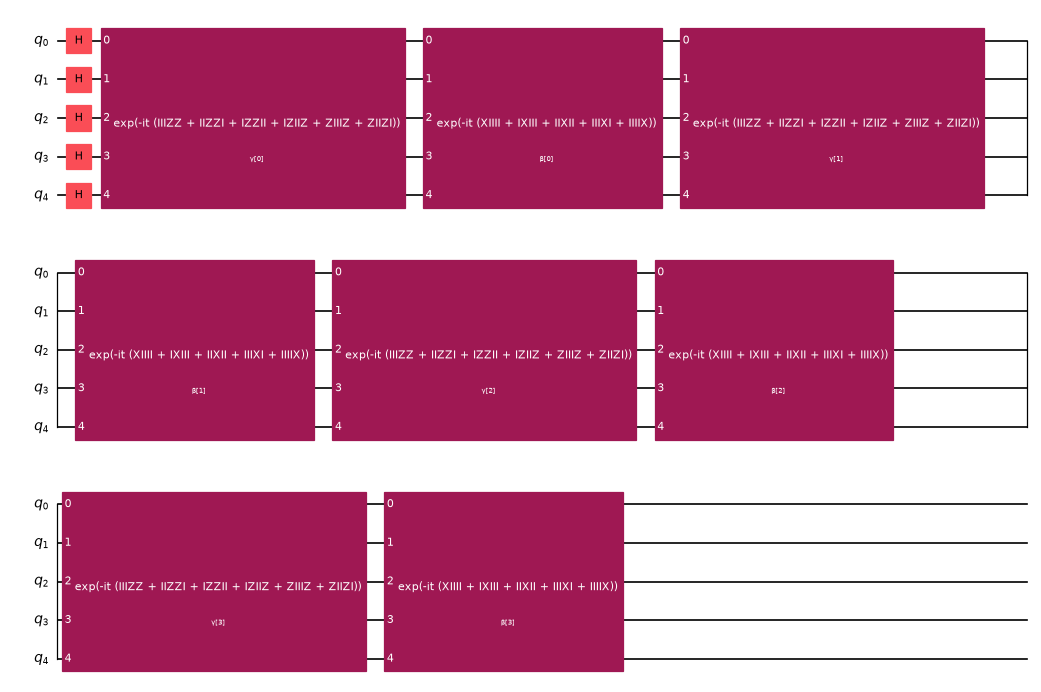

In [8]:
# ---------------------------------------------------------------------------
# Hyperparameter search for QAOA
# ---------------------------------------------------------------------------
# For each number of layers we:
#   1. sample random angles and add structured linear-ramp points,
#   2. keep the candidates with the highest exact P(optimal),
#   3. polish them with COBYLA,
#   4. keep the parameters with the highest exact P(optimal).
#
# The objective is the grader's metric (probability of an exact optimum), not
# the expected energy. For the weighted problem these two objectives differ,
# especially at low depth, so optimizing <H> alone leaves probability on
# near-optimal cuts.

layers_range = list(range(1, 5))
num_samples = 20_000
num_polish = 100
search_results = []
best_by_layer = {}


def _ramp_points(p):
    """Structured linear-ramp initial points (known to work well for QAOA)."""
    points = []
    for d in (0.2, 0.3, 0.4, 0.5, 0.6):
        betas = np.array([(1.0 - i / p) * d for i in range(p)])
        gammas = np.array([((i + 1.0) / p) * d for i in range(p)])
        points.append(np.concatenate([betas, gammas]))
    return points


for p in layers_range:
    # Fixed per-layer seed: deterministic and reproducible.
    rng = np.random.default_rng(42)
    random_points = np.concatenate(
        [
            rng.uniform(0.0, np.pi, size=(num_samples, p)),
            rng.uniform(0.0, 2.0 * np.pi, size=(num_samples, p)),
        ],
        axis=1,
    )
    candidates = np.vstack([random_points, np.array(_ramp_points(p))])
    scores = np.array([exact_metrics(candidate, p)[1] for candidate in candidates])
    top_indices = np.argsort(scores)[::-1][:num_polish]

    layer_candidates = []
    for index in top_indices:
        result = minimize(
            lambda x: -exact_metrics(x, p)[1],
            candidates[index],
            method="COBYLA",
            options={"rhobeg": 0.1, "maxiter": 500, "tol": 1e-6},
        )
        energy, p_optimal = exact_metrics(result.x, p)
        layer_candidates.append(
            {
                "num_layers": p,
                "params": result.x.copy(),
                "energy": energy,
                "p_optimal": p_optimal,
            }
        )

    layer_candidates.sort(key=lambda r: (-r["p_optimal"], r["energy"]))
    best_for_p = layer_candidates[0]
    best_by_layer[p] = best_for_p
    search_results.extend(layer_candidates)

    print(
        f"p={p:2d} | best <H>={best_for_p['energy']:+.4f} | "
        f"P(optimal)={100.0 * best_for_p['p_optimal']:.2f}%"
    )

# Select by the grader metric, then by energy, then by the smallest circuit.
search_results.sort(key=lambda r: (-r["p_optimal"], r["energy"], r["num_layers"]))
best_result = search_results[0]

num_layers = best_result["num_layers"]
opt_params = best_result["params"]
opt_cost = best_result["energy"]

# Rebuild the final circuit with the selected number of layers.
circuit_qaoa = QAOAAnsatz(H, reps=num_layers)

print()
print(f"Selected number of layers : {num_layers}")
print(f"Exact <H>                 : {opt_cost:+.4f}")
print(f"Exact P(optimal)          : {100.0 * best_result['p_optimal']:.2f}%")
print("Selected parameters       :", np.round(opt_params, 6).tolist())

# Show the final circuit
circuit_qaoa.decompose(reps=1).draw(output="mpl", scale=0.6)


## Reading the search results

The table above reports, for each number of layers, the best exact `<H>` and the
best exact probability of measuring an optimal bitstring. In the executed run:

- `p=1` reaches `P(optimal) ≈ 30.0%` with `<H> ≈ -0.831`.
- `p=2` reaches `P(optimal) ≈ 55.2%` with `<H> ≈ -1.583`.
- `p=3` reaches `P(optimal) ≈ 80.5%` with `<H> ≈ -2.792`.
- `p=4` reaches `P(optimal) ≈ 90.1%` with `<H> ≈ -3.007`.

The exact minimum is `<H> = -3.308`, so `p=4` captures about 90.9% of the
achievable energy while placing about 90% of the probability on the two optimal
bitstrings. The search selects `p=4` because it has the largest overlap with the
optimal subspace. The exact statevector evaluation is cheap for five qubits, so
this larger search is practical and avoids the variance of the noisy estimator.


## Visualizing the QAOA landscape

The plots below make the optimization problem visible:

- the two-parameter `p=1` landscape, where the full success surface can be drawn;
- the layer sweep, showing how the best success probability improves with depth;
- the spread of final scores across all multi-start candidates;
- the optimized angle schedule for the selected `p=4` circuit;
- the final statevector distribution, with the optimal bitstrings highlighted.


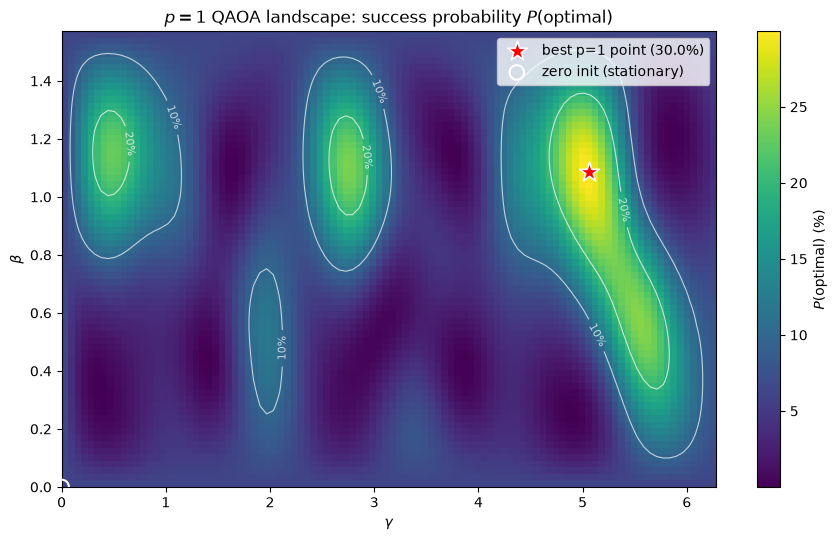

In [9]:
# Full 2D landscape for p=1: only two angles (beta, gamma) are needed.
landscape_betas = np.linspace(0.0, np.pi / 2.0, 70)
landscape_gammas = np.linspace(0.0, 2.0 * np.pi, 100)
P_landscape = np.zeros((len(landscape_betas), len(landscape_gammas)))

for i, beta in enumerate(landscape_betas):
    for j, gamma in enumerate(landscape_gammas):
        _, p_optimal = exact_metrics(np.array([beta, gamma]), 1)
        P_landscape[i, j] = 100.0 * p_optimal

fig, ax = plt.subplots(figsize=(9, 5.5))
image = ax.imshow(
    P_landscape,
    origin="lower",
    aspect="auto",
    extent=[0.0, 2.0 * np.pi, 0.0, np.pi / 2.0],
    cmap="viridis",
)
contours = ax.contour(
    landscape_gammas,
    landscape_betas,
    P_landscape,
    levels=[10, 20, 30],
    colors="white",
    linewidths=0.8,
    alpha=0.7,
)
ax.clabel(contours, inline=True, fontsize=8, fmt="%d%%")

p1_best = best_by_layer[1]["params"]
ax.scatter(
    p1_best[1] % (2.0 * np.pi),
    p1_best[0],
    marker="*",
    s=220,
    color="red",
    edgecolor="white",
    linewidth=1.2,
    label=f"best p=1 point ({100.0 * best_by_layer[1]['p_optimal']:.1f}%)",
)
ax.scatter(
    0.0,
    0.0,
    marker="o",
    s=110,
    facecolor="none",
    edgecolor="white",
    linewidth=1.5,
    label="zero init (stationary)",
    zorder=5,
)
ax.set_xlabel(r"$\gamma$")
ax.set_ylabel(r"$\beta$")
ax.set_title(r"$p=1$ QAOA landscape: success probability $P(\mathrm{optimal})$")
ax.legend(loc="upper right")
fig.colorbar(image, ax=ax, label=r"$P(\mathrm{optimal})$ (%)")
plt.tight_layout()
plt.show()


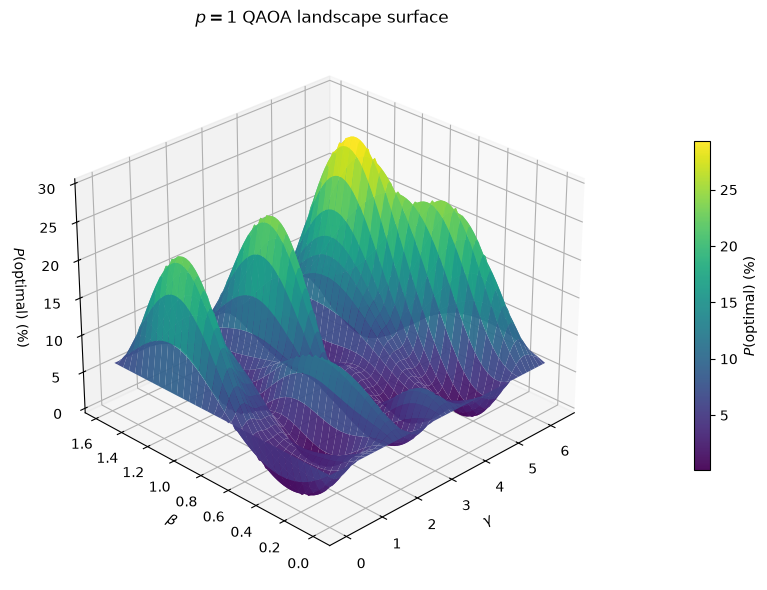

In [10]:
# 3D view of the same p=1 landscape.
BETA_GRID, GAMMA_GRID = np.meshgrid(landscape_betas, landscape_gammas, indexing="ij")

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="3d")
surface = ax.plot_surface(
    GAMMA_GRID,
    BETA_GRID,
    P_landscape,
    cmap="viridis",
    linewidth=0,
    antialiased=True,
    alpha=0.95,
)
ax.set_xlabel(r"$\gamma$")
ax.set_ylabel(r"$\beta$")
ax.set_zlabel(r"$P(\mathrm{optimal})$ (%)")
ax.set_title(r"$p=1$ QAOA landscape surface")
ax.view_init(elev=28, azim=-135)
fig.colorbar(surface, ax=ax, shrink=0.6, pad=0.1, label=r"$P(\mathrm{optimal})$ (%)")
plt.tight_layout()
plt.show()


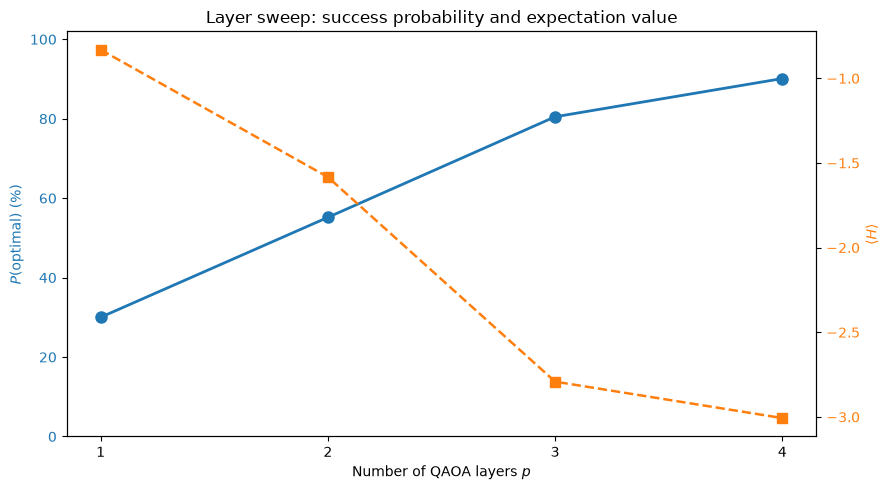

In [11]:
# Best success probability and energy for each number of layers.
layer_values = sorted(best_by_layer)
best_probabilities = [100.0 * best_by_layer[p]["p_optimal"] for p in layer_values]
best_energies = [best_by_layer[p]["energy"] for p in layer_values]

fig, ax_prob = plt.subplots(figsize=(9, 5))
ax_prob.plot(layer_values, best_probabilities, "o-", color="tab:blue", linewidth=2, markersize=8)
ax_prob.set_xlabel("Number of QAOA layers $p$")
ax_prob.set_ylabel(r"$P(\mathrm{optimal})$ (%)", color="tab:blue")
ax_prob.tick_params(axis="y", labelcolor="tab:blue")
ax_prob.set_xticks(layer_values)
ax_prob.set_ylim(0, 102)

ax_energy = ax_prob.twinx()
ax_energy.plot(layer_values, best_energies, "s--", color="tab:orange", linewidth=1.8, markersize=7)
ax_energy.set_ylabel(r"$\langle H \rangle$", color="tab:orange")
ax_energy.tick_params(axis="y", labelcolor="tab:orange")

ax_prob.set_title("Layer sweep: success probability and expectation value")
fig.tight_layout()
plt.show()


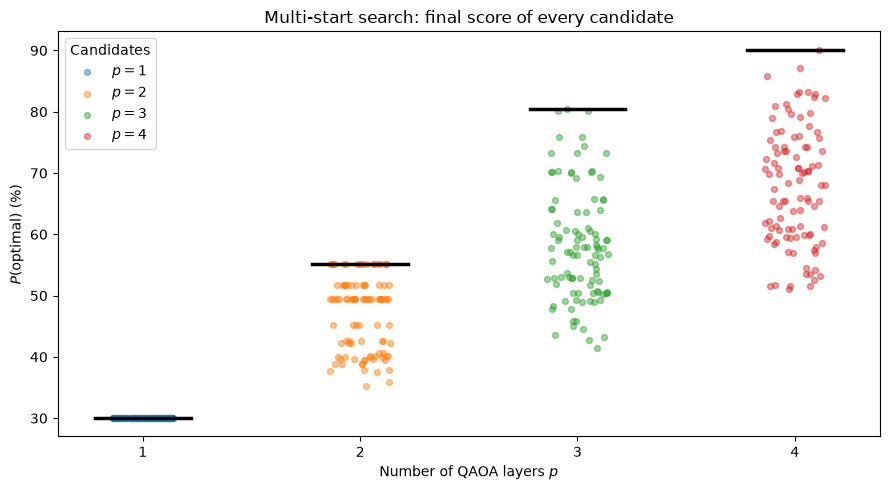

In [12]:
# Every candidate from the multi-start search, grouped by number of layers.
fig, ax = plt.subplots(figsize=(9, 5))
jitter_rng = np.random.default_rng(0)

for p in sorted(best_by_layer):
    values = [100.0 * result["p_optimal"] for result in search_results if result["num_layers"] == p]
    x_positions = p + jitter_rng.uniform(-0.14, 0.14, size=len(values))
    ax.scatter(x_positions, values, s=18, alpha=0.45, label=f"$p={p}$")
    ax.plot(
        [p - 0.22, p + 0.22],
        [100.0 * best_by_layer[p]["p_optimal"]] * 2,
        color="black",
        linewidth=2.5,
    )

ax.set_xlabel("Number of QAOA layers $p$")
ax.set_ylabel(r"$P(\mathrm{optimal})$ (%)")
ax.set_title("Multi-start search: final score of every candidate")
ax.set_xticks(sorted(best_by_layer))
ax.legend(title="Candidates")
fig.tight_layout()
plt.show()


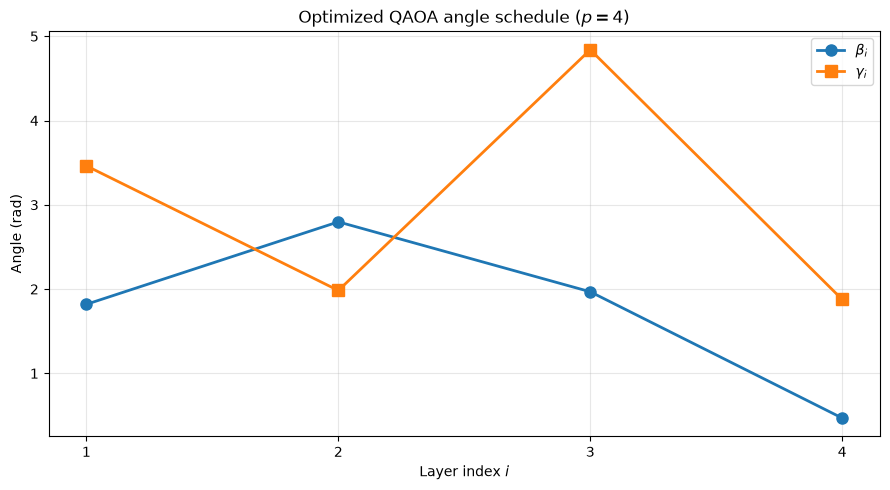

In [13]:
# Optimized angle schedule for the selected circuit.
layer_indices = np.arange(1, num_layers + 1)
betas = opt_params[:num_layers]
gammas = opt_params[num_layers:]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(layer_indices, betas, "o-", linewidth=2, markersize=8, label=r"$\beta_i$")
ax.plot(layer_indices, gammas, "s-", linewidth=2, markersize=8, label=r"$\gamma_i$")
ax.set_xlabel("Layer index $i$")
ax.set_ylabel("Angle (rad)")
ax.set_title(f"Optimized QAOA angle schedule ($p={num_layers}$)")
ax.set_xticks(layer_indices)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


/home/mf/miniconda3/envs/qest-ibm/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/mf/miniconda3/envs/qest-ibm/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/home/mf/miniconda3/envs/qest-ibm/lib/python3.13/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


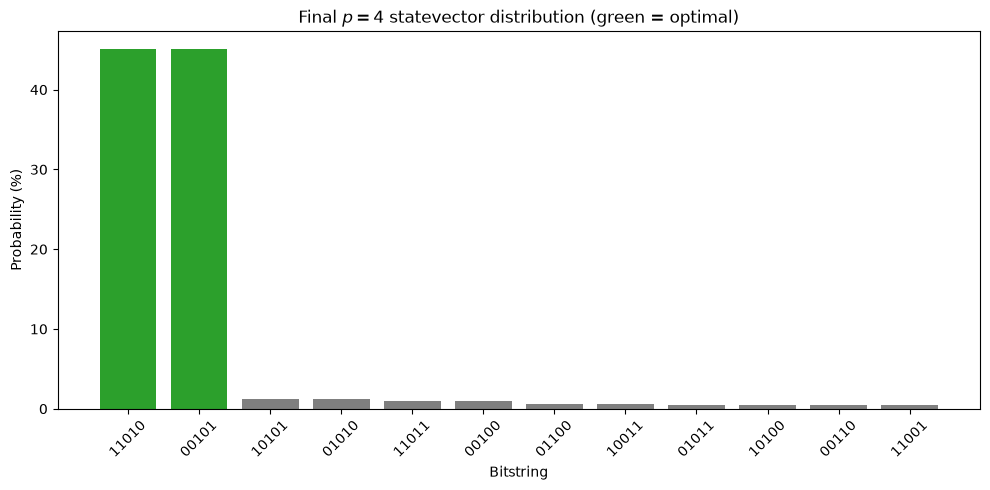

In [14]:
# Exact final distribution, highlighting the optimal bitstrings.
final_state = Statevector(
    QAOAAnsatz(H, reps=num_layers).assign_parameters(opt_params)
)
final_probabilities = final_state.probabilities_dict()
top_outcomes = sorted(final_probabilities.items(), key=lambda item: item[1], reverse=True)[:12]

labels = [bitstring for bitstring, _ in top_outcomes]
values = [100.0 * probability for _, probability in top_outcomes]
colors = ["tab:green" if bitstring in optimal_set else "tab:gray" for bitstring in labels]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(labels, values, color=colors)
ax.set_xlabel("Bitstring")
ax.set_ylabel("Probability (%)")
ax.set_title(f"Final $p={num_layers}$ statevector distribution (green = optimal)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()


# Evaluation of the solution

The search above chooses the angles using exact statevector probabilities. This
section checks the same circuit with the challenge scoring helper:

- The circuit is sampled with `Sampler` to obtain a probability distribution.
- `utils.compute_score` draws 100,000 shots and returns the percentage of shots
  that land on an optimal bitstring.
- The exact `P(optimal)` from the statevector is the expected value of that
  score, so the sampled score should be close to it.

A high score means the QAOA circuit amplifies the optimal maintenance schedules
and suppresses the suboptimal ones.


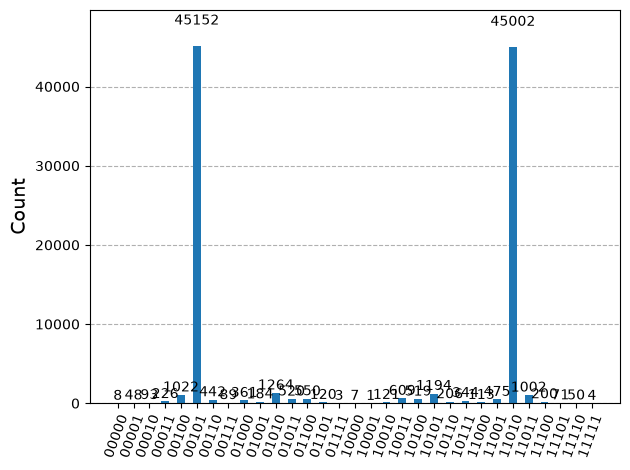

In [15]:
# Instantiate a Sampler to obtain a probability distribution
sampler = Sampler(mode=backend)
sampler.options.default_shots = 100_000

# Compute the probability distribution with the optimal parameters you found during optimization.
circuit_qaoa_copy = circuit_qaoa.decompose(reps=2).copy()
circuit_qaoa_copy.measure_all()
circuit_qaoa_copy.draw()
counts = sampler.run([(circuit_qaoa_copy, opt_params)]).result()[0].data.meas.get_counts()

# Display the probability distribution
plot_histogram(counts)


Most probable quantum outcomes:
  00101  probability= 45.15%  cost=-43  schedule: S0=P2, S1=P1, S2=P2, S3=P1, S4=P1
  11010  probability= 45.00%  cost=-43  schedule: S0=P1, S1=P2, S2=P1, S3=P2, S4=P2
  01010  probability=  1.26%  cost=-37  schedule: S0=P1, S1=P2, S2=P1, S3=P2, S4=P1
  10101  probability=  1.19%  cost=-37  schedule: S0=P2, S1=P1, S2=P2, S3=P1, S4=P2
  00100  probability=  1.02%  cost=+25  schedule: S0=P1, S1=P1, S2=P2, S3=P1, S4=P1

Quantum solution : 00101  (45.15% of shots)
  schedule      : S0=P2, S1=P1, S2=P2, S3=P1, S4=P1
  cost          : -43  (exact minimum: -43)
  expected cost : -39.0868  (exact minimum: -43.0000)


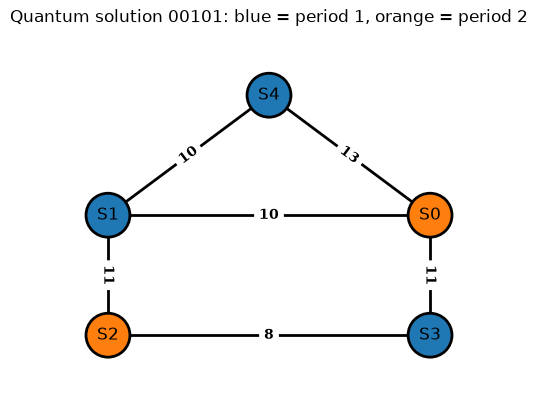

In [16]:
# Decode the measured bitstrings into a maintenance schedule.
# Qiskit uses the leftmost character for the highest qubit, so the rightmost
# bit is qubit 0 (station S0).
def bitstring_cost(bitstring: str) -> int:
    """Cost of a measured bitstring for the weighted Hamiltonian (sum of w_ij Z_i Z_j)."""
    bits = {node: int(bitstring[-1 - node]) for node in G.nodes}
    return sum(
        weight * (1 if bits[u] == bits[v] else -1)
        for u, v, weight in G.edges(data="weight")
    )

def schedule(bitstring: str) -> str:
    """Human-readable period assignment for a measured bitstring."""
    return ", ".join(
        f"S{node}={'P2' if int(bitstring[-1 - node]) else 'P1'}"
        for node in sorted(G.nodes)
    )

num_samples = sum(counts.values())
ranked = sorted(counts.items(), key=lambda item: item[1], reverse=True)

print("Most probable quantum outcomes:")
for bitstring, count in ranked[:5]:
    print(
        f"  {bitstring}  probability={100 * count / num_samples:6.2f}%  "
        f"cost={bitstring_cost(bitstring):+d}  schedule: {schedule(bitstring)}"
    )

best_bitstring, best_count = ranked[0]
print(f"\nQuantum solution : {best_bitstring}  ({100 * best_count / num_samples:.2f}% of shots)")
print(f"  schedule      : {schedule(best_bitstring)}")
print(f"  cost          : {bitstring_cost(best_bitstring):+d}  (exact minimum: {minimum_cost * max_weight:+.0f})")

expected_cost = sum(
    count / num_samples * bitstring_cost(bitstring)
    for bitstring, count in counts.items()
)
print(f"  expected cost : {expected_cost:.4f}  (exact minimum: {minimum_cost * max_weight:.4f})")

# Draw the quantum assignment on the problem graph
draw_options = {**options, "node_color": [
    "tab:blue" if int(best_bitstring[-1 - node]) == 0 else "tab:orange"
    for node in G.nodes
]}
nx.draw_networkx(G, pos, **draw_options)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10, font_weight="bold")
plt.title(f"Quantum solution {best_bitstring}: blue = period 1, orange = period 2")
ax = plt.gca()
ax.margins(0.20)
plt.axis("off")
plt.show()


In [17]:
# Evaluate the optimized parameters with the scoring helpers from utils.py
print("Exact minimum cost :", minimum_cost)
print("Exact optimal solutions :", binary_sols)

# Sampled score and expectation value for the QAOA parameters found above
qaoa_cost, qaoa_score = utils.compute_score(
    params=opt_params, num_layers=num_layers, hamiltonian=H
)
print(f"QAOA score : {qaoa_score:.2f}% of shots on an optimal solution")
print(f"QAOA expected cost : {qaoa_cost:.4f} (exact minimum: {minimum_cost:.4f})")
print(f"QAOA optimal bitstring: {best_bitstring}")


Exact minimum cost : -3.3076923076923075
Exact optimal solutions : ['00101', '11010']
Optimal cost :  -3.0086477021381177
Score :  90.14999999999999
QAOA score : 90.15% of shots on an optimal solution
QAOA expected cost : -3.0086 (exact minimum: -3.3077)
QAOA optimal bitstring: 00101


# Save your results

Finally, don't forget to save your results using the `save_res` method available in `utils.py`.

The code below writes `coop_problem_2.npz`. Replace `coop` with your team name if needed. You can check the content of your `.npz` file using the `read_res` method also available in `utils.py`.


In [18]:
utils.save_res(filename="coop_problem_2.npz", params=opt_params, num_layers=num_layers, hamiltonian=H)


# Running the final circuit on an IBM Quantum QPU

The search above uses exact statevector simulation to choose the angles. This
final section submits the selected QAOA circuit to a real IBM Quantum backend
so the hardware result can be compared with the ideal simulation.

The QPU run uses the least-busy operational backend with at least five qubits
and a modest number of shots (4096). The circuit is transpiled to the backend's
native gates and connectivity before submission.

Hardware noise and the transpiled circuit depth usually make the QPU score lower
than the exact statevector score. The key check is whether the most probable
hardware outcomes are still the optimal bitstrings.

The cell below is guarded by `RUN_ON_QPU`; set it to `True` to submit a hardware
job. It is disabled by default so the notebook can be re-run without spending
QPU time.


In [ ]:
RUN_ON_QPU = True  # Set to True to submit a job to a real QPU (requires IBM Quantum account and credits)

if RUN_ON_QPU:
    from qiskit_ibm_runtime import QiskitRuntimeService

    # Connect to IBM Quantum and choose a real (non-simulator) backend.
    service = QiskitRuntimeService()
    qpu = service.least_busy(operational=True, simulator=False, min_num_qubits=H.num_qubits)
    print(f"QPU backend   : {qpu.name} ({qpu.num_qubits} qubits)")
    print(f"Pending jobs  : {qpu.status().pending_jobs}")

    # Bind the selected angles, measure, and transpile for the QPU.
    qpu_circuit = QAOAAnsatz(H, reps=num_layers).assign_parameters(opt_params)
    qpu_circuit.measure_all()
    pm_qpu = generate_preset_pass_manager(backend=qpu, optimization_level=2)
    isa_qpu_circuit = pm_qpu.run(qpu_circuit)
    print(f"Transpiled depth: {isa_qpu_circuit.depth()}")

    # Submit the hardware job.
    qpu_sampler = Sampler(mode=qpu)
    qpu_sampler.options.default_shots = 4096
    qpu_job = qpu_sampler.run([(isa_qpu_circuit,)])
    print(f"QPU job id    : {qpu_job.job_id()}")
    qpu_counts = qpu_job.result()[0].data.meas.get_counts()

    # Score the hardware result with the same criterion as the grader.
    qpu_shots = sum(qpu_counts.values())
    qpu_optimal_counts = sum(
        count for bitstring, count in qpu_counts.items() if bitstring in optimal_set
    )
    qpu_score = 100.0 * qpu_optimal_counts / qpu_shots

    print(f"QPU shots     :
Finally, don't forget to save your results using the `save_res` method available in `utils.py`.

The code below writes `coop_problem_1.npz`. Replace `coop` with your team name if needed. You can check the content of your `.npz` file using the `read_res` method also available in `utils.py`. {qpu_shots}")
    print(f"QPU score     : {qpu_score:.2f}% of shots on an optimal solution")
    print("QPU top outcomes:")
    for bitstring, count in sorted(qpu_counts.items(), key=lambda item: item[1], reverse=True)[:5]:
        print(
            f"  {bitstring}  probability={100.0 * count / qpu_shots:6.2f}%  "
            f"cost={bitstring_cost(bitstring):+d}"
        )

    plot_histogram(qpu_counts)
else:
    print("QPU run skipped (set RUN_ON_QPU = True to submit a hardware job).")


QPU backend   : ibm_chicago (120 qubits)
Pending jobs  : 0
Transpiled depth: 206
QPU job id    : dbqmc26jjaos73ahi4fg
QPU shots     : 4096
QPU score     : 68.07% of shots on an optimal solution
QPU top outcomes:
  00101  probability= 34.81%  cost=-43
  11010  probability= 33.25%  cost=-43
  01010  probability=  5.18%  cost=-37
  10101  probability=  4.03%  cost=-37
  00111  probability=  2.08%  cost=-21


# Takeaways
